<center><h1>Peng_Yu-Hsuan_HW6</h1></center>

Name: Yu-Hsuan Peng
<br>
Github Username: Vincent2k0624
<br>
USC ID: 1889-9849-82

## 1. Tree-Based Methods

Import packages

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.base import clone
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression

### (a) Download the APS Failure data

In [2]:
train_data = pd.read_csv('aps_failure_training_set.csv', skiprows = 20, na_values = 'na')
test_data = pd.read_csv('aps_failure_test_set.csv', skiprows = 20, na_values = 'na')

print("Train data : ", train_data.shape)
print("Test data : ", test_data.shape)

train_data.head()

Train data :  (60000, 171)
Test data :  (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common techniques: deleting rows or features, mean/median imputation, missing-value indicators, model-based imputation (regression, k-NN, MICE), multiple imputation, and algorithms that handle missing values natively (e.g. XGBoost). Deletion is not feasible here because 59,409 of 60,000 training rows have missing values. I use median imputation, which is robust to extreme values. As in the assignment footnote, the test set is imputed with its own medians.

In [3]:
X_train = train_data.drop(columns = 'class')
y_train = train_data['class']

X_test = test_data.drop(columns = 'class')
y_test = test_data['class']

In [4]:
train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(X_test.median())

print('Missing values in training data : ', X_train.isna().sum().sum())
print('Missing values in test data : ', X_test.isna().sum().sum())

Missing values in training data :  0
Missing values in test data :  0


#### (ii) Calculate the coefficient of variation

In [5]:
feature_means = X_train.mean()
feature_stds = X_train.std(ddof = 1)

cv = feature_stds / feature_means.replace(0, np.nan)

cv_table = pd.DataFrame({'Mean' : feature_means, 'Standard Deviation' : feature_stds, 'CV' : cv})
cv_table = cv_table.sort_values('CV', ascending = False)

cv_table.head(13)

,Mean,Standard Deviation,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


#### (iii) Plot a correlation matrix

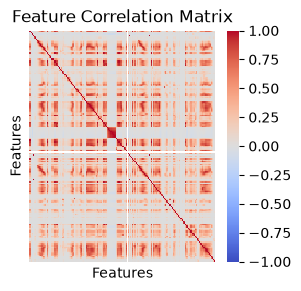

In [6]:
correlation_matrix = X_train.corr()

plt.figure(figsize=(3, 3))

sns.heatmap(correlation_matrix, cmap = "coolwarm", vmin = -1, vmax = 1, center = 0, xticklabels = False, yticklabels = False)

plt.title("Feature Correlation Matrix")
plt.xlabel("Features")
plt.ylabel("Features")
plt.show()

#### (iv) Make scatter plots and box plots

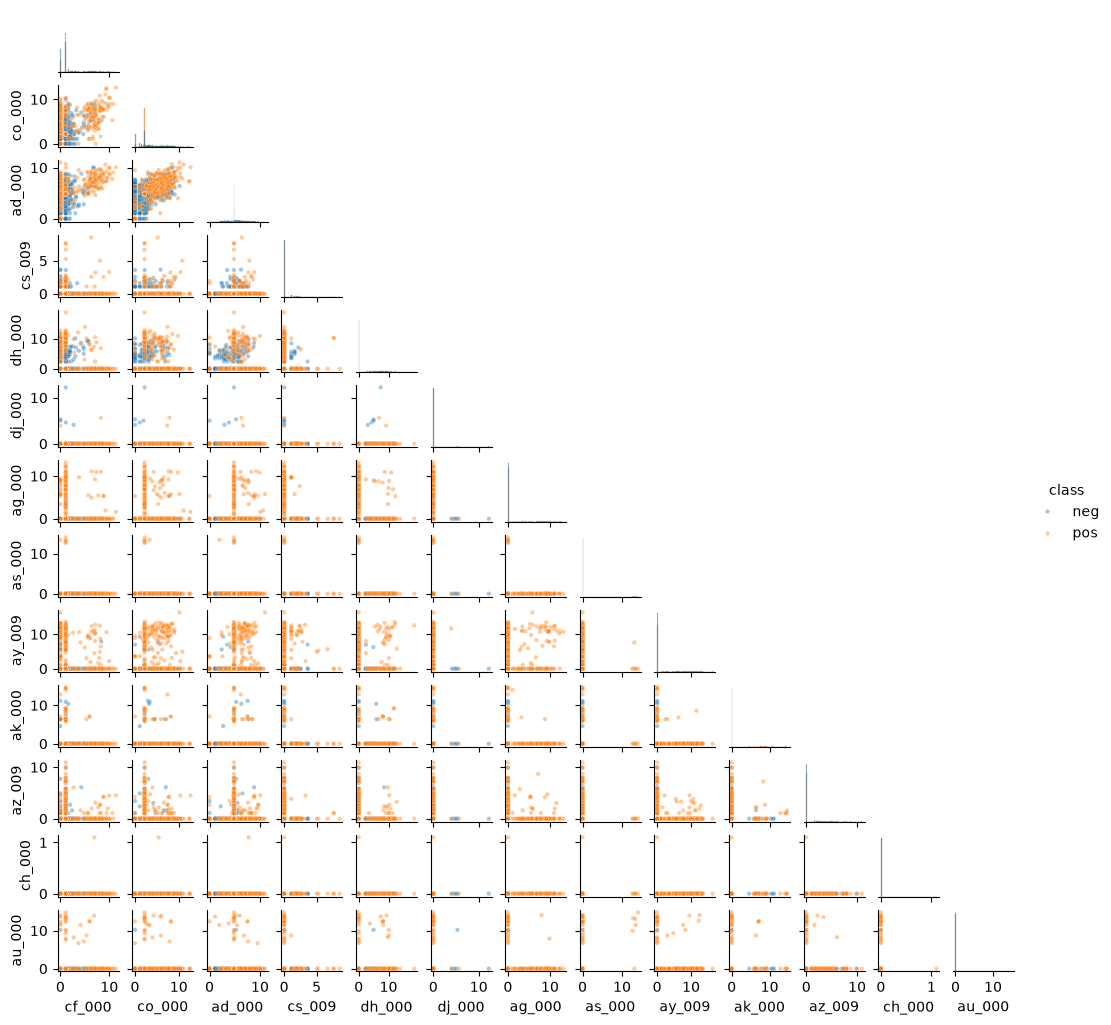

In [7]:
top_features = cv_table.head(13).index

plot_data = X_train[top_features].copy()
plot_data['class'] = y_train

sample_neg = plot_data[plot_data['class'] == 'neg'].sample(n = 1000, random_state = 42)
sample_pos = plot_data[plot_data['class'] == 'pos']
plot_sample = pd.concat([sample_neg, sample_pos])

plot_sample[top_features] = np.log1p(plot_sample[top_features])

sns.pairplot(plot_sample, hue = 'class', diag_kind = 'hist', plot_kws = {'alpha' : 0.4, 's' : 10}, height = 0.8, corner = True, )
plt.show()

The scatter plots use log(1 + x) of the features because they are highly right-skewed.

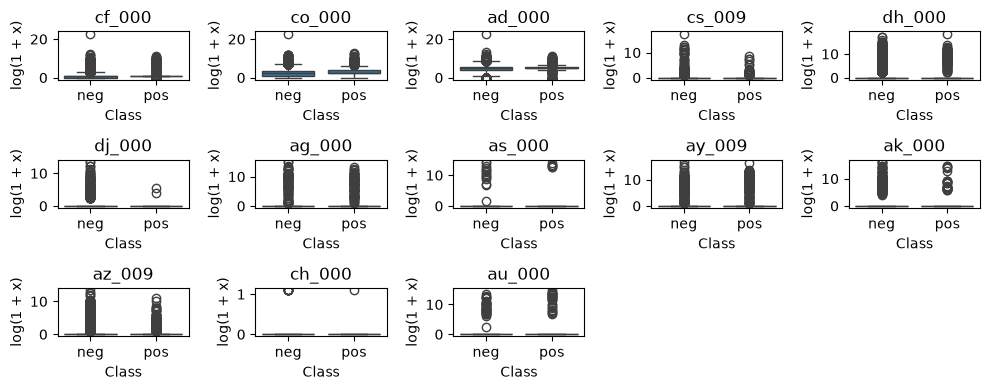

In [8]:
top_features = cv_table.head(13).index

box_data = X_train[top_features].copy()
box_data[top_features] = np.log1p(box_data[top_features])
box_data["class"] = y_train

fig, axes = plt.subplots(3, 5, figsize=(10, 4))

for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(data = box_data, x = "class", y = feature, order = ["neg", "pos"], ax = ax)

    ax.set_title(feature)
    ax.set_xlabel("Class")
    ax.set_ylabel("log(1 + x)")

for ax in axes.flat[13:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Only the first few features (`cf_000`, `co_000`, `ad_000`) show a visible shift between the classes: their `pos` observations tend to have larger values. For the remaining features the `neg` and `pos` distributions overlap almost completely, since most values are zero with a few extreme outliers. A high CV mostly reflects these outliers and does not imply predictive importance, so significance cannot be concluded from the scatter plots and box plots alone.

#### (v) Is this data set imbalanced?

In [9]:
class_counts = pd.DataFrame({"Training" : y_train.value_counts(), "Test" : y_test.value_counts()})
class_counts

,Training,Test
class,,
neg,59000,15625
pos,1000,375


Yes. The training set contains 59,000 negative and 1,000 positive observations, while the test set contains 15,625 negative and 375 positive observations. The dataset is highly imbalanced because negative observations greatly outnumber positive observations.

### (c) Train a random forest

In [10]:
rf_model = RandomForestClassifier(oob_score = True, random_state = 42, n_jobs = -1)
rf_model.fit(X_train, y_train)

,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.

In [11]:
y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)
oob_error = 1 - rf_model.oob_score_

print("Training misclassification error:", train_error)
print("Test misclassification error:", test_error)
print("OOB error:", oob_error)

Training misclassification error: 1.666666666666483e-05
Test misclassification error: 0.0075625000000000275
OOB error: 0.006116666666666659


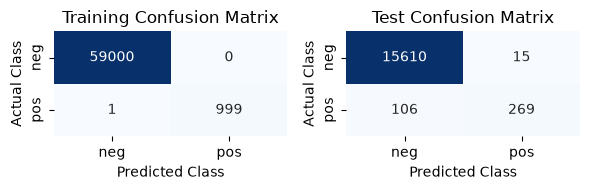

In [12]:
train_cm = confusion_matrix(y_train, y_train_pred, labels = ["neg", "pos"])

test_cm = confusion_matrix(y_test, y_test_pred, labels = ["neg", "pos"])

fig, axes = plt.subplots(1, 2, figsize = (6, 2))

for ax, cm, title in zip(axes, [train_cm, test_cm], ["Training Confusion Matrix", "Test Confusion Matrix"]):
    sns.heatmap(cm,annot = True, fmt = "d", cmap = "Blues", cbar = False,xticklabels = ["neg", "pos"], yticklabels = ["neg", "pos"], ax = ax)

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

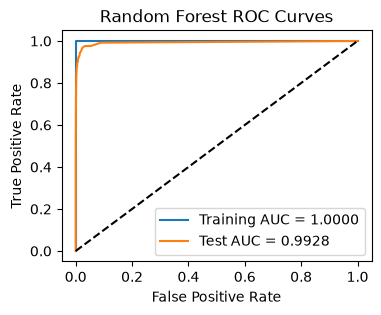

Training AUC: 1.0
Test AUC: 0.9927662079999999


In [13]:
pos_index = list(rf_model.classes_).index("pos")

y_train_prob = rf_model.predict_proba(X_train)[:, pos_index]
y_test_prob = rf_model.predict_proba(X_test)[:, pos_index]

y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)

train_auc = roc_auc_score(y_train_binary, y_train_prob)
test_auc = roc_auc_score(y_test_binary, y_test_prob)

train_fpr, train_tpr, _ = roc_curve(y_train_binary, y_train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test_binary, y_test_prob)

plt.figure(figsize=(4, 3))

plt.plot(train_fpr, train_tpr, label = f"Training AUC = {train_auc:.4f}")
plt.plot(test_fpr, test_tpr, label = f"Test AUC = {test_auc:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

print("Training AUC:", train_auc)
print("Test AUC:", test_auc)

The training and test misclassification errors are 0.00167% and 0.75625%, respectively. The OOB error is 0.61167%, which is close to but slightly lower than the test error.  
The training AUC is approximately 1.0000, and the test AUC is 0.9928. Despite the high test AUC, the model misses 106 of 375 positive observations, giving a positive-class recall of 71.73%.

### (d) Research class imbalance in random forest

Class imbalance in random forests can be handled by class weights, balanced bootstrap samples (balanced random forest), over-sampling such as SMOTE, or a lower decision threshold. I use `class_weight='balanced_subsample'`, which weights the classes inversely to their frequencies within each bootstrap sample.

In [14]:
rf_balanced = RandomForestClassifier(class_weight = "balanced_subsample", oob_score = True, random_state = 42, n_jobs = -1)

rf_balanced.fit(X_train, y_train)

y_train_pred_balanced = rf_balanced.predict(X_train)
y_test_pred_balanced = rf_balanced.predict(X_test)

train_error_balanced = 1 - accuracy_score(y_train, y_train_pred_balanced)
test_error_balanced = 1 - accuracy_score(y_test, y_test_pred_balanced)
oob_error_balanced = 1 - rf_balanced.oob_score_

print("Training misclassification error:", train_error_balanced)
print("Test misclassification error:", test_error_balanced)
print("OOB error:", oob_error_balanced)

Training misclassification error: 1.666666666666483e-05
Test misclassification error: 0.010937500000000044
OOB error: 0.008033333333333337


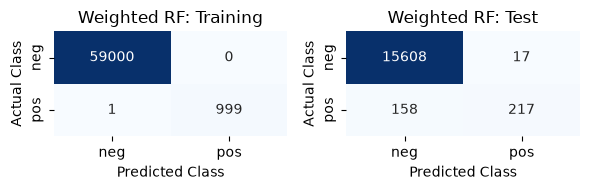

In [15]:
train_cm_balanced = confusion_matrix(y_train, y_train_pred_balanced, labels = ["neg", "pos"])

test_cm_balanced = confusion_matrix(y_test, y_test_pred_balanced, labels = ["neg", "pos"])

fig, axes = plt.subplots(1, 2, figsize=(6, 2))

for ax, cm, title in zip(axes, [train_cm_balanced, test_cm_balanced], ["Weighted RF: Training", "Weighted RF: Test"]):
    sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues", cbar = False, xticklabels = ["neg", "pos"], yticklabels = ["neg", "pos"], ax = ax)

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

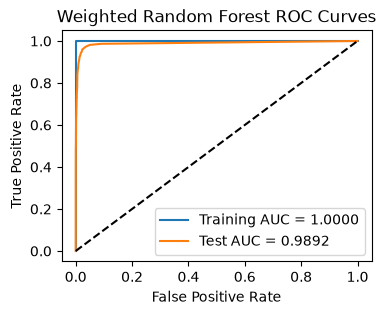

Training AUC: 1.0
Test AUC: 0.9891584853333333


In [16]:
pos_index_balanced = list(rf_balanced.classes_).index("pos")

y_train_prob_balanced = rf_balanced.predict_proba(X_train)[:, pos_index_balanced]

y_test_prob_balanced = rf_balanced.predict_proba(X_test)[:, pos_index_balanced]

train_auc_balanced = roc_auc_score(y_train_binary, y_train_prob_balanced)
test_auc_balanced = roc_auc_score(y_test_binary, y_test_prob_balanced)

train_fpr_balanced, train_tpr_balanced, _ = roc_curve(y_train_binary, y_train_prob_balanced)
test_fpr_balanced, test_tpr_balanced, _ = roc_curve(y_test_binary, y_test_prob_balanced)

plt.figure(figsize = (4, 3))

plt.plot(train_fpr_balanced, train_tpr_balanced, label = f"Training AUC = {train_auc_balanced:.4f}")
plt.plot(test_fpr_balanced, test_tpr_balanced, label = f"Test AUC = {test_auc_balanced:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Weighted Random Forest ROC Curves")
plt.legend()
plt.show()

print("Training AUC:", train_auc_balanced)
print("Test AUC:", test_auc_balanced)

I use `class_weight="balanced_subsample"` to address class imbalance by weighting classes inversely to their frequencies within each bootstrap sample.  
The training, test, and OOB errors are 0.00167%, 1.09375%, and 0.80333%, respectively. The training and test AUCs are 1.0000 and 0.9892.  
Compared with the unweighted model, the test error increases, while the test AUC and the positive-class recall decrease (the model now misses 158 of 375 positive observations, a recall of 57.87%, compared with 71.73% before). Thus, class weighting does not improve performance in this experiment. The OOB error (0.80333%) is lower than the test error (1.09375%).

### (e) XGBoost and Model Trees

In [17]:
X_train_raw = train_data.drop(columns = "class")
X_test_raw = test_data.drop(columns = "class")

y_train_binary = (y_train == "pos").astype(int)
y_test_binary = (y_test == "pos").astype(int)

In [18]:
xgb_pipeline = Pipeline([("imputer", SimpleImputer(strategy = "median")), ("scaler", StandardScaler()), ("model", XGBClassifier(
        booster = "gblinear", objective = "binary:logistic", reg_lambda = 0, updater = "coord_descent", learning_rate = 0.01,
        n_estimators = 2000, base_score = 0.5, random_state = 42, n_jobs = 1))])

alpha_grid = {"model__reg_alpha": [0, 0.0001, 0.001, 0.01, 0.1]}

cv_folds = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

xgb_search = GridSearchCV(xgb_pipeline, param_grid = alpha_grid, scoring = "accuracy",
    cv = cv_folds, n_jobs = -1, verbose = 0, error_score = "raise")

xgb_search.fit(X_train_raw, y_train_binary)

best_xgb = xgb_search.best_estimator_

print("Best parameters:", xgb_search.best_params_)
print("CV misclassification error:", 1 - xgb_search.best_score_)

Best parameters: {'model__reg_alpha': 0}
CV misclassification error: 0.00886666666666669


In [19]:
y_train_pred_xgb = best_xgb.predict(X_train_raw)
y_test_pred_xgb = best_xgb.predict(X_test_raw)

train_error_xgb = 1 - accuracy_score(y_train_binary, y_train_pred_xgb)

test_error_xgb = 1 - accuracy_score(y_test_binary, y_test_pred_xgb)

cv_error_xgb = 1 - xgb_search.best_score_

print("Training misclassification error:", train_error_xgb)
print("Test misclassification error:", test_error_xgb)
print("CV misclassification error:", cv_error_xgb)

Training misclassification error: 0.007933333333333348
Test misclassification error: 0.010750000000000037
CV misclassification error: 0.00886666666666669


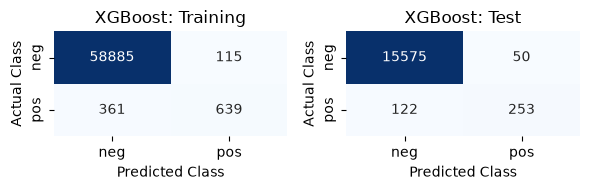

In [20]:
train_cm_xgb = confusion_matrix(y_train_binary, y_train_pred_xgb, labels = [0, 1])

test_cm_xgb = confusion_matrix(y_test_binary, y_test_pred_xgb, labels = [0, 1])

fig, axes = plt.subplots(1, 2, figsize = (6, 2))

for ax, cm, title in zip(axes, [train_cm_xgb, test_cm_xgb], ["XGBoost: Training", "XGBoost: Test"]):
    sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues", cbar = False, xticklabels = ["neg", "pos"], yticklabels = ["neg", "pos"], ax = ax)

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

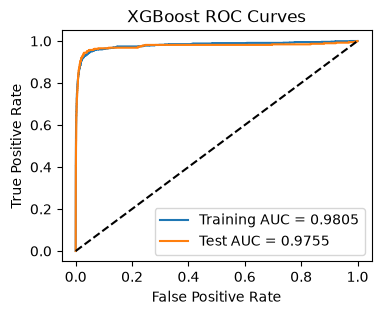

Training AUC: 0.9805041355932204
Test AUC: 0.9754669226666667


In [21]:
y_train_prob_xgb = best_xgb.predict_proba(X_train_raw)[:, 1]
y_test_prob_xgb = best_xgb.predict_proba(X_test_raw)[:, 1]

train_auc_xgb = roc_auc_score(y_train_binary, y_train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test_binary, y_test_prob_xgb)

train_fpr_xgb, train_tpr_xgb, _ = roc_curve(y_train_binary, y_train_prob_xgb)
test_fpr_xgb, test_tpr_xgb, _ = roc_curve(y_test_binary, y_test_prob_xgb)

plt.figure(figsize = (4, 3))

plt.plot(train_fpr_xgb, train_tpr_xgb, label = f"Training AUC = {train_auc_xgb:.4f}")
plt.plot(test_fpr_xgb, test_tpr_xgb, label = f"Test AUC = {test_auc_xgb:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.show()

print("Training AUC:", train_auc_xgb)
print("Test AUC:", test_auc_xgb)

I use XGBoost's `gblinear` booster with logistic loss, which fits a global linear logistic model rather than logistic models within tree nodes. No class-imbalance compensation is applied.  
Five-fold cross-validation selects alpha = 0, with 2,000 update rounds fixed. Thus, the selected model has no L1 penalty.  
The training, CV, and test misclassification errors are 0.79333%, 0.88667%, and 1.075%, respectively. The CV error is slightly lower than the test error.  
The training and test AUCs are 0.9805 and 0.9755, respectively.  
In (e) and (f), imputation and scaling are part of the pipeline and are fitted on the training data only, so cross-validation does not leak information from the validation folds.

In [22]:
l1_pipeline = Pipeline([("imputer", SimpleImputer(strategy = "median")), ("scaler", StandardScaler()), ("model", LogisticRegression(l1_ratio = 1, solver = "liblinear", max_iter = 200))])

l1_search = GridSearchCV(l1_pipeline, param_grid = {"model__C" : [0.1, 0.3, 1, 3, 10, 30]}, scoring = "accuracy", cv = cv_folds, n_jobs = -1)

l1_search.fit(X_train_raw, y_train_binary)

best_l1 = l1_search.best_estimator_

print("Best C:", l1_search.best_params_["model__C"])
print("CV misclassification error:", 1 - l1_search.best_score_)
print("Non-zero coefficients:", int((best_l1.named_steps["model"].coef_ != 0).sum()), "of", X_train_raw.shape[1])

Best C: 1
CV misclassification error: 0.008549999999999947
Non-zero coefficients: 153 of 170


Training misclassification error: 0.0074666666666666215
Test misclassification error: 0.010249999999999981
CV misclassification error: 0.008549999999999947


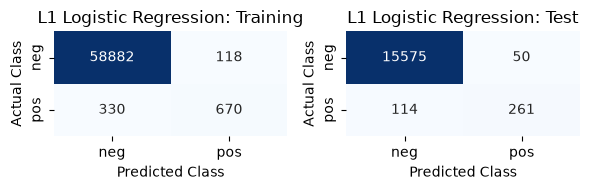

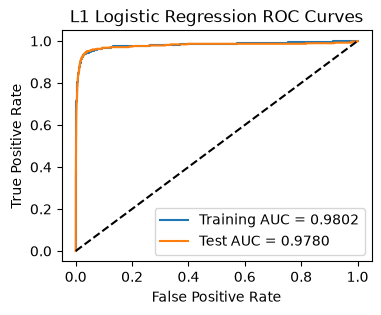

Training AUC: 0.9801997966101694
Test AUC: 0.9779803306666667


In [23]:
y_train_pred_l1 = best_l1.predict(X_train_raw)
y_test_pred_l1 = best_l1.predict(X_test_raw)

train_error_l1 = 1 - accuracy_score(y_train_binary, y_train_pred_l1)
test_error_l1 = 1 - accuracy_score(y_test_binary, y_test_pred_l1)
cv_error_l1 = 1 - l1_search.best_score_

print("Training misclassification error:", train_error_l1)
print("Test misclassification error:", test_error_l1)
print("CV misclassification error:", cv_error_l1)

train_cm_l1 = confusion_matrix(y_train_binary, y_train_pred_l1, labels = [0, 1])
test_cm_l1 = confusion_matrix(y_test_binary, y_test_pred_l1, labels = [0, 1])

fig, axes = plt.subplots(1, 2, figsize = (6, 2))

for ax, cm, title in zip(axes, [train_cm_l1, test_cm_l1], ["L1 Logistic Regression: Training", "L1 Logistic Regression: Test"]):
    sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues", cbar = False, xticklabels = ["neg", "pos"], yticklabels = ["neg", "pos"], ax = ax)

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

y_train_prob_l1 = best_l1.predict_proba(X_train_raw)[:, 1]
y_test_prob_l1 = best_l1.predict_proba(X_test_raw)[:, 1]

train_auc_l1 = roc_auc_score(y_train_binary, y_train_prob_l1)
test_auc_l1 = roc_auc_score(y_test_binary, y_test_prob_l1)

train_fpr_l1, train_tpr_l1, _ = roc_curve(y_train_binary, y_train_prob_l1)
test_fpr_l1, test_tpr_l1, _ = roc_curve(y_test_binary, y_test_prob_l1)

plt.figure(figsize = (4, 3))

plt.plot(train_fpr_l1, train_tpr_l1, label = f"Training AUC = {train_auc_l1:.4f}")
plt.plot(test_fpr_l1, test_tpr_l1, label = f"Test AUC = {test_auc_l1:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("L1 Logistic Regression ROC Curves")
plt.legend()
plt.show()

print("Training AUC:", train_auc_l1)
print("Test AUC:", test_auc_l1)

I also fit an L1-penalized logistic regression on all features (a single global linear model, the simplest case of a model tree), again without compensating for class imbalance. The regularization parameter C (the inverse of the penalty strength) is chosen by 5-fold cross-validation, and the selected value is C = 1, which keeps 153 of the 170 coefficients non-zero.  
The training, CV, and test misclassification errors are 0.74667%, 0.855%, and 1.025%, respectively. The CV error is slightly lower than the test error.  
The training and test AUCs are 0.9802 and 0.9780, and the test set contains 50 false positives and 114 false negatives (positive-class recall of 69.60%).  
Compared with the `gblinear` model, the L1 logistic regression has a slightly lower test error and a slightly higher test AUC and recall.

### (f) Use SMOTE to pre-process your data

To save computation time, alpha is searched over {0, 0.001, 0.01}.

In [24]:
smote_pipeline = ImbPipeline([("imputer", SimpleImputer(strategy = "median")), ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state = 42)), ("model", clone(best_xgb.named_steps["model"]).set_params(n_jobs = 1))])

smote_search = GridSearchCV(smote_pipeline, param_grid = {"model__reg_alpha": [0, 0.001, 0.01]}, scoring = "accuracy",
    cv = cv_folds, n_jobs = -1, verbose = 0, error_score = "raise")

smote_search.fit(X_train_raw, y_train_binary)

best_xgb_smote = smote_search.best_estimator_

print("Best alpha:", smote_search.best_params_["model__reg_alpha"])
print("CV misclassification error:", 1 - smote_search.best_score_)

Best alpha: 0.001
CV misclassification error: 0.02406666666666679


In [25]:
y_train_pred_smote = best_xgb_smote.predict(X_train_raw)
y_test_pred_smote = best_xgb_smote.predict(X_test_raw)

train_error_smote = 1 - accuracy_score(y_train_binary, y_train_pred_smote)
test_error_smote = 1 - accuracy_score(y_test_binary, y_test_pred_smote)
cv_error_smote = 1 - smote_search.best_score_

print("Training misclassification error:", train_error_smote)
print("Test misclassification error:", test_error_smote)
print("CV misclassification error:", cv_error_smote)

Training misclassification error: 0.023433333333333306
Test misclassification error: 0.023625000000000007
CV misclassification error: 0.02406666666666679


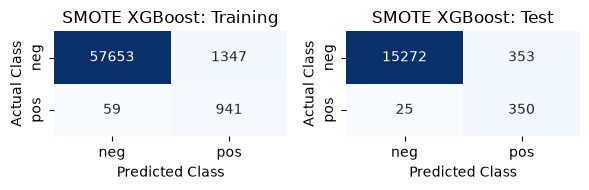

In [26]:
train_cm_smote = confusion_matrix(y_train_binary, y_train_pred_smote, labels=[0, 1])
test_cm_smote = confusion_matrix(y_test_binary, y_test_pred_smote, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize = (6, 2))

for ax, cm, title in zip(axes,[train_cm_smote, test_cm_smote],["SMOTE XGBoost: Training", "SMOTE XGBoost: Test"]):
    sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues", cbar = False, xticklabels = ["neg", "pos"], yticklabels = ["neg", "pos"], ax = ax)

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

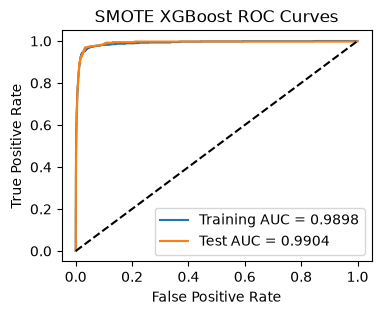

Training AUC: 0.9897923559322033
Test AUC: 0.9903785813333332


In [27]:
y_train_prob_smote = best_xgb_smote.predict_proba(X_train_raw)[:, 1]
y_test_prob_smote = best_xgb_smote.predict_proba(X_test_raw)[:, 1]

train_auc_smote = roc_auc_score(y_train_binary, y_train_prob_smote)
test_auc_smote = roc_auc_score(y_test_binary, y_test_prob_smote)

train_fpr_smote, train_tpr_smote, _ = roc_curve(y_train_binary, y_train_prob_smote)
test_fpr_smote, test_tpr_smote, _ = roc_curve(y_test_binary, y_test_prob_smote)

plt.figure(figsize=(4, 3))

plt.plot(train_fpr_smote, train_tpr_smote, label = f"Training AUC = {train_auc_smote:.4f}")
plt.plot(test_fpr_smote, test_tpr_smote, label = f"Test AUC = {test_auc_smote:.4f}")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SMOTE XGBoost ROC Curves")
plt.legend()
plt.show()

print("Training AUC:", train_auc_smote)
print("Test AUC:", test_auc_smote)

SMOTE is applied only within each CV training fold, after imputation and standardization, to avoid data leakage. Validation and test data are not resampled.  
With 2,000 update rounds fixed from (e), five-fold CV selects alpha = 0.001. The training, CV, and test errors are 2.34333%, 2.40667%, and 2.3625%, respectively. The CV error is close to the test error.  
The training and test AUCs are 0.9898 and 0.9904.  
Compared with (e), test AUC increases from 0.9755 to 0.9904, and positive-class recall increases from 67.47% to 93.33%. However, false positives increase from 50 to 353, raising test error from 1.075% to 2.3625%. Thus, SMOTE improves failure detection at the cost of more false alarms.

## 2. ISLR 6.6.3

(a) iv. Training RSS is nonincreasing because increasing s relaxes the constraint.

(b) ii. Test RSS typically decreases initially and then increases due to overfitting.

(c) iii. Variance typically increases as the model becomes more flexible.

(d) iv. Squared bias typically decreases as the constraint becomes less restrictive.

(e) v. Irreducible error remains constant because it does not depend on s.

## 3. ISLR 6.6.5

(a) Since the data are centered, the intercept estimate is zero. Let x11 = x12 = a, x21 = x22 = -a, y1 = b, y2 = -b. The ridge optimization problem is

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2
+\lambda(\beta_1^2+\beta_2^2).
$$

(b) Since the two predictors are identical, the RSS depends only on $\beta_1+\beta_2$. For a fixed sum, $\beta_1^2+\beta_2^2$ is minimized when $\beta_1=\beta_2$. Thus, ridge gives equal coefficients when $\lambda>0$.

(c) The lasso optimization problem is

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2
+\lambda(|\beta_1|+|\beta_2|).
$$

(d) Let the optimal coefficient sum be $t$. If $t>0$, every pair $(u,t-u)$ with $0\le u\le t$ has the same RSS and L1 penalty. If $t<0$, the same holds for $t\le u\le0$. Therefore, the coefficients are not unique when $t\ne0$.

If the penalty shrinks the optimal sum to zero and $\lambda>0$, the unique solution is $(0,0)$.

## 4. ISLR 8.4.5

Majority vote predicts Red because 6 of the 10 trees assign Red a probability greater than 0.5.  
Averaging probabilities predicts Green because the average Red probability is 0.45, which is below 0.5.

## 5. ISLR 9.7.3

(a) The seven observations are plotted below.

(b) The optimal separating hyperplane is
$$
0.5-X_1+X_2=0.
$$
The support vectors lie on the lines X2 = X1 and X2 = X1 - 1, so the optimal hyperplane is the line halfway between them, $X_2 = X_1 - 0.5$.

(c) Classify an observation as Red if $0.5-X_1+X_2>0$, and Blue otherwise. Thus, $\beta_0=0.5$, $\beta_1=-1$, and $\beta_2=1$.

(d) The margin boundaries are $X_2=X_1$ and $X_2=X_1-1$. The perpendicular distance from the separator to either boundary is $1/(2\sqrt{2})$.

(e) Observations 2, 3, 5, and 6 are the support vectors because they lie on the margin boundaries.

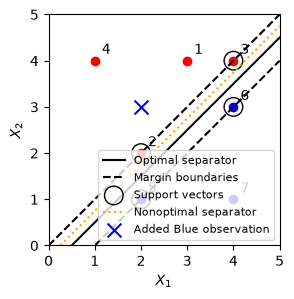

In [28]:
points = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])

colors = ["red"] * 4 + ["blue"] * 3

plt.figure(figsize = (3, 3))

for i, (x1, x2) in enumerate(points):
    plt.scatter(x1, x2, color=colors[i])
    plt.annotate(str(i + 1), (x1, x2), xytext = (5, 5), textcoords = "offset points")

x = np.linspace(0, 5, 100)

plt.plot(x, x - 0.5, "k-", label = "Optimal separator")
plt.plot(x, x, "k--", label = "Margin boundaries")
plt.plot(x, x - 1, "k--")

support_points = points[[1, 2, 4, 5]]

plt.scatter(support_points[:, 0], support_points[:, 1], s = 180, facecolors = "none", edgecolors = "black", label = "Support vectors")

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.gca().set_aspect("equal")
# (g) A separating line with a smaller margin
plt.plot(x, x - 0.25, color = "orange", linestyle = ":", label = "Nonoptimal separator")

# (h) An additional Blue observation
plt.scatter(2, 3, color = "blue", marker = "x", s = 100, label = "Added Blue observation")
plt.legend(loc = "lower right", fontsize = 8)
plt.show()

(f) Observation 7 is not a support vector. A small movement that keeps it beyond the Blue margin boundary does not change the optimal separating hyperplane.

(g) Another separating hyperplane is $X_2=X_1-0.25$. It separates the original classes but has a smaller margin than the optimal separator.

(h) Adding a Blue observation at $(2,3)$ makes the classes no longer linearly separable. This point lies inside the convex hull of the Red observations, so no straight line can separate all Red and Blue observations.